<a href="https://colab.research.google.com/github/gbenihonkenoukon-dotcom/AI-for-Science-and-Engineering-online-course/blob/main/Week_5_Assignment_Gbenihon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Week 5 Assignment | Building Supervised Machine Learning Model**

Target/output: Strain

Features to predict it: Stress and Void ratio

The problem is a regression problem.
Indeed, the target (strain) is a continuous numerical quantity, not a category or a label.

In [1]:
#Loading training and testing data

from google.colab import files

uploaded = files.upload()

Saving Testing data.xlsx to Testing data.xlsx
Saving Dataset for training_Organized.xlsx to Dataset for training_Organized.xlsx


Because I am using data from oedometer tests curves, I cannot split the dataset into training and test sets randomly. Testing and training dataset should contains values for the same specimen curve. So, to not have data point (from the same curve/same specimen/same test) in both training and testind dataset, I splited per specimen/test/curve in two differents excel sheets.

In [3]:
import pandas as pd

# Load the two Excel files
train_data = pd.read_excel("Dataset for training_Organized.xlsx")
test_data = pd.read_excel("Testing data.xlsx")

# Count the number of observations
n_train = len(train_data)
n_test = len(test_data)

# Calculate total observations
n_total = n_train + n_test

# Calculate percentages
train_percentage = (n_train / n_total) * 100
test_percentage = (n_test / n_total) * 100

# Display results
print("Training observations:", n_train)
print("Testing observations:", n_test)
print("Total observations:", n_total)
print(f"Training percentage: {train_percentage:.2f}%")
print(f"Testing percentage: {test_percentage:.2f}%")


Training observations: 1183
Testing observations: 660
Total observations: 1843
Training percentage: 64.19%
Testing percentage: 35.81%


So, my split ratio is 64.19:35.81. A training proportion of 64.19% and a testing proportion of 35.81%.

**First supervised learning model: Decision Trees**

Decision Tree Regression Results
--------------------------------
R²   : 0.8068
RMSE : 0.049760
MAE  : 0.036241


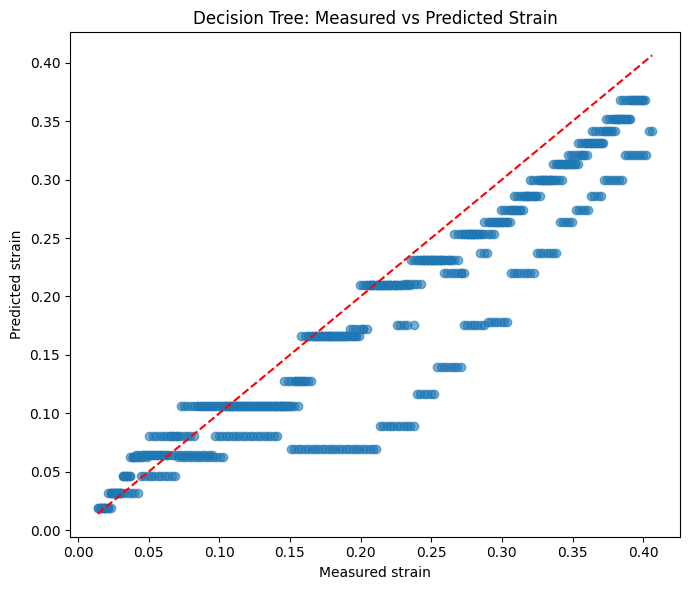

Predictions saved to decision_tree_predictions.xlsx


In [10]:


import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



# 2. Select input variables and target variable
X_train = train_data[["stress", "void ratio"]]
y_train = train_data["strain"]

X_test = test_data[["stress", "void ratio"]]
y_test = test_data["strain"]

# 3. Create the Decision Tree Regression model
model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=5,
    random_state=42
)

# 4. Train the model
model.fit(X_train, y_train)

# 5. Predict strain for the testing dataset
y_pred = model.predict(X_test)

# 6. Evaluate model performance
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("Decision Tree Regression Results")
print("--------------------------------")
print(f"R²   : {r2:.4f}")
print(f"RMSE : {rmse:.6f}")
print(f"MAE  : {mae:.6f}")

# 7. Plot measured versus predicted strain
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

# Reference line: perfect predictions
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Measured strain")
plt.ylabel("Predicted strain")
plt.title("Decision Tree: Measured vs Predicted Strain")
plt.tight_layout()
plt.show()

# 8. Save predictions to an Excel file
results = test_data.copy()
results["predicted_strain"] = y_pred
results.to_excel("decision_tree_predictions.xlsx", index=False)

print("Predictions saved to decision_tree_predictions.xlsx")


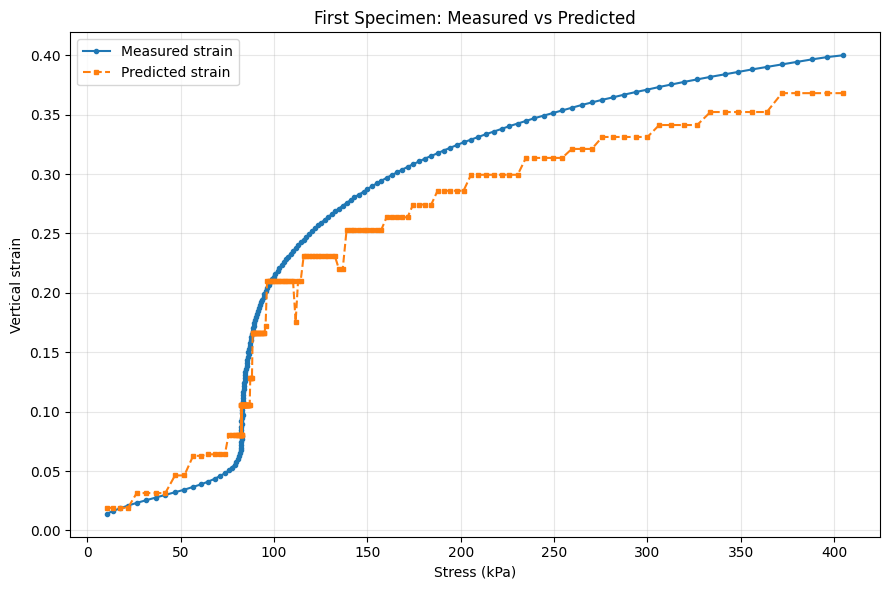

In [11]:
#ploting of stress-strain curves

# Select the first specimen: Excel rows 2–167
start = 0
end = 166  # Python slicing excludes the end position

# Extract stress, measured strain, and predicted strain
curve = pd.DataFrame({
    "stress": X_test["stress"].iloc[start:end].to_numpy(),
    "measured_strain": y_test.iloc[start:end].to_numpy(),
    "predicted_strain": y_pred[start:end]
})

# Sort observations by stress
curve = curve.sort_values("stress")

# Plot measured and predicted curves
plt.figure(figsize=(9, 6))

plt.plot(
    curve["stress"],
    curve["measured_strain"],
    "o-",
    markersize=3,
    label="Measured strain"
)

plt.plot(
    curve["stress"],
    curve["predicted_strain"],
    "s--",
    markersize=3,
    label="Predicted strain"
)

plt.xlabel("Stress (kPa)")
plt.ylabel("Vertical strain")
plt.title("First Specimen: Measured vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Second model: ANN**

ANN Regression Results
-----------------------
R²   : 0.7486
RMSE : 0.056758
MAE  : 0.038953


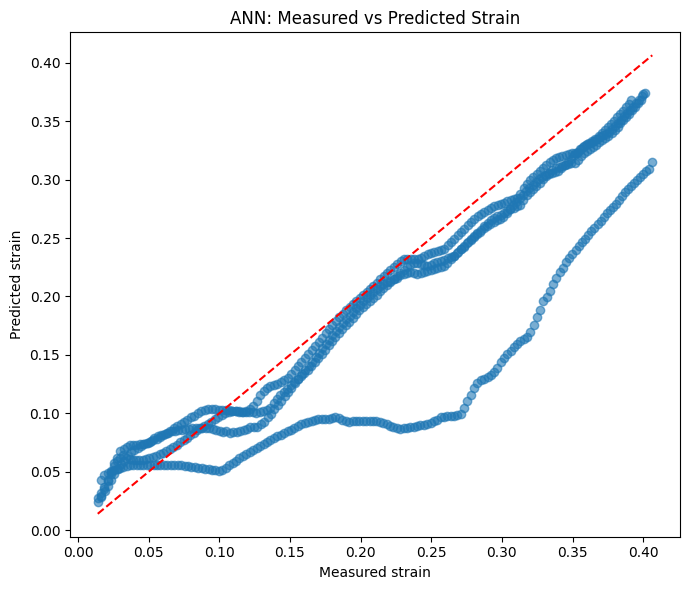

Predictions saved to ann_predictions.xlsx


In [14]:


from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline


# 3. Create the ANN model
# Scaling is fitted on training data only, through the pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("ann", MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=42
    ))
])

# 4. Train the ANN
model.fit(X_train, y_train)

# 5. Predict strain on the test dataset
y_pred = model.predict(X_test)

# 6. Evaluate model performance
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("ANN Regression Results")
print("-----------------------")
print(f"R²   : {r2:.4f}")
print(f"RMSE : {rmse:.6f}")
print(f"MAE  : {mae:.6f}")

# 7. Plot measured versus predicted strain
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

# Reference line for perfect predictions
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Measured strain")
plt.ylabel("Predicted strain")
plt.title("ANN: Measured vs Predicted Strain")
plt.tight_layout()
plt.show()

# 8. Save predictions to an Excel file
results = test_data.copy()
results["predicted_strain"] = y_pred
results.to_excel("ann_predictions.xlsx", index=False)

print("Predictions saved to ann_predictions.xlsx")


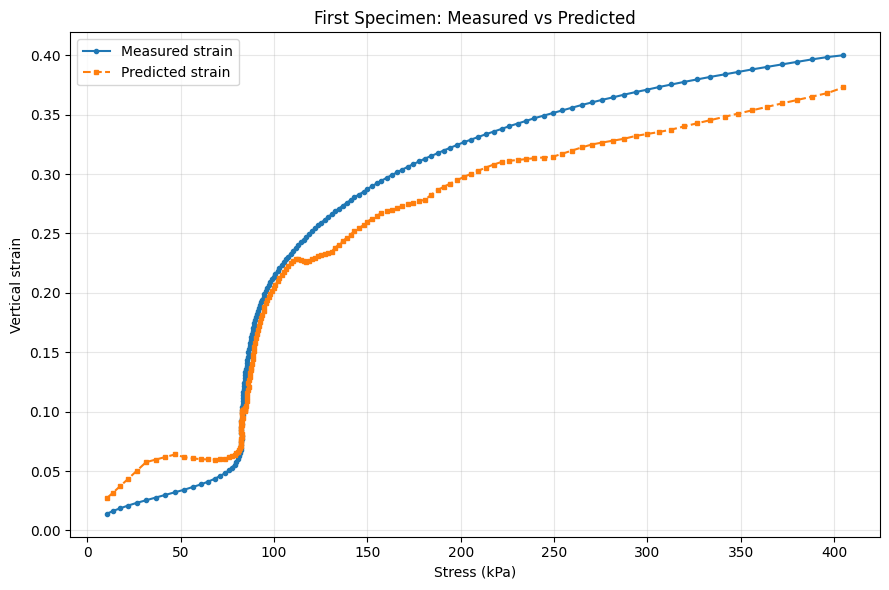

In [15]:


# Select the first specimen: Excel rows 2–167
start = 0
end = 166  # Python slicing excludes the end position

# Extract stress, measured strain, and predicted strain
curve = pd.DataFrame({
    "stress": X_test["stress"].iloc[start:end].to_numpy(),
    "measured_strain": y_test.iloc[start:end].to_numpy(),
    "predicted_strain": y_pred[start:end]
})

# Sort observations by stress
curve = curve.sort_values("stress")

# Plot measured and predicted curves
plt.figure(figsize=(9, 6))

plt.plot(
    curve["stress"],
    curve["measured_strain"],
    "o-",
    markersize=3,
    label="Measured strain"
)

plt.plot(
    curve["stress"],
    curve["predicted_strain"],
    "s--",
    markersize=3,
    label="Predicted strain"
)

plt.xlabel("Stress (kPa)")
plt.ylabel("Vertical strain")
plt.title("First Specimen: Measured vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Performance comparison and discussion**
The metrics rank the Decision Tree as the best performative model (Higher \(R^2\), lower RMSE and MAE), suggesting that its predictions capture substantial variation in the measured strain.

However, the predicted curve shape is not smooth. Decision Trees typically produce stepwise predictions because each terminal leaf assigns a constant predicted value to observations within that region. Consequently, the predicted stress–strain curve contain horizontal plateaus and abrupt jumps rather than a smooth progression.

The ANN on the other hand can represent continuous nonlinear relationships and produced smoother curves.

The most appropriate model for geotechnical prediction would be judged by both numerical accuracy and physical plausibility.
